# What do the reasoning traces contain, and what changes when the model reasons more?

Traces are loaded from each run’s `output/.../<run_id>/reasoning_traces/*.jsonl`.
(`run_comparison.ipynb` still writes derived eval helpers if needed.)
and the evaluation files used here).

**Approach**

1. Split every reasoning trace into sentences.
2. Flag sentences that merely copy the prompt instructions (cosine similarity to an instruction sentence > 0.85).
3. Sentence-level topic model (BERTopic: MiniLM embeddings → UMAP → k-means with 40 clusters). Whole traces
   are not used as documents because they mostly differ by the page content, not by the reasoning.
4. The 40 topics are grouped by hand into a small codebook of *reasoning moves* (section 4). This grouping is an
   interpretation and should be checked against the keywords and example sentences shown there.
5. Where does additional reasoning go (per run)? Which moves co-occur with correct and wrong pages?
6. **Flip analysis**: the same page solved by two runs, once wrong and once right. These pairs are the most direct
   evidence of what longer reasoning changes. Each comparison is set against pages that both runs got right.

**Caveats**: all runs have reasoning enabled; there is no reasoning-off baseline yet. Traces are not guaranteed to
reflect the model's actual computation, so all results describe what traces *contain*, not what *causes* a
correct answer. The flip counts are small; read them qualitatively.

In [ ]:
import hashlib
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)

ROOT = Path.cwd().resolve()
if not (ROOT / "output").is_dir():
    ROOT = ROOT.parent
OUT = ROOT / "output"
DERIVED = ROOT / "analysis" / "derived"
TOPIC_DIR = DERIVED / "topics"
TOPIC_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
DS = "DeepSeek-V4-Flash-0731"

RUN_DIRS = {
    "gpt-oss low": OUT / "gpt-oss-120b_low" / "1ebb0c8dc26d4681bda9555908104e67",
    "gpt-oss medium": OUT / "gpt-oss-120b_medium" / "8b438992f14c4b6da28ec581572dcc85",
    "gpt-oss high": OUT / "gpt-oss-120b_high" / "10d7970dd8304f8cb06d174a851f8e2a",
    "DeepSeek high": OUT / f"{DS}_high" / "2c50bb4fcde3462f9d6cbe6516b686c9",
    "DeepSeek max": OUT / f"{DS}_max" / "4c3229ed86dc4fe6b1ef4b95c64ca68d",
}
RUN_ORDER = list(RUN_DIRS)
EVAL_DIRS = {run: d for run, d in RUN_DIRS.items()}  # eval CSVs live in the same run folders
EXCLUDE = {"everi holdings_2019_report.pdf"}
EMBED_MODEL = "all-MiniLM-L6-v2"
PROMPT_COPY_THRESHOLD = 0.85

rows = []
for run, run_dir in RUN_DIRS.items():
    for path in sorted((run_dir / "reasoning_traces").glob("*.jsonl")):
        with path.open(encoding="utf-8") as f:
            for i, line in enumerate(f):
                c = json.loads(line)
                reasoning = c.get("reasoning_content")
                if not reasoning or not str(reasoning).strip():
                    continue
                report = Path(str(c["pdf"]).replace("\\", "/")).name
                if report in EXCLUDE:
                    continue
                rows.append({
                    "run": run,
                    "report": report,
                    "page": str(i),  # call index as stand-in; no separate page field in jsonl
                    "call_index": i,
                    "prompt": c.get("prompt"),
                    "reasoning": reasoning,
                    "answer": c.get("content"),
                    "category": "unknown",
                    "n_gold_page": 0,
                    "n_tp_page": 0,
                    "n_fp_page": 0,
                    "n_fn_page": 0,
                })

pages = pd.DataFrame(rows)
pages["run"] = pd.Categorical(pages["run"], RUN_ORDER, ordered=True)
pages = pages.sort_values(["run", "report", "call_index"]).reset_index(drop=True)
pages["trace_id"] = np.arange(len(pages))
pages.groupby("run", observed=True).size().rename("traces").to_frame()

,traces
run,
gpt-oss low,966
gpt-oss medium,966
gpt-oss high,966
DeepSeek high,965
DeepSeek max,960


## 1. Sentence segmentation

Traces are split at line breaks and at sentence ends followed by an upper-case letter or quote. Fragments with
fewer than three words (e.g. "JSON.") are dropped.

In [2]:
SPLIT = re.compile(r"\n+|(?<=[.!?])\s+(?=[A-Z\"'(\[])")


def segments(text):
    out = []
    for s in SPLIT.split(text or ""):
        s = re.sub(r"\s+", " ", s).strip(" -*•\t")
        if len(s.split()) >= 3:
            out.append(s)
    return out


seg = pd.DataFrame([(r.trace_id, j, s) for r in pages.itertuples() for j, s in enumerate(segments(r.reasoning))],
                   columns=["trace_id", "pos", "text"])
seg = seg.merge(pages[["trace_id", "run"]], on="trace_id")
seg["rel_pos"] = seg.pos / seg.groupby("trace_id").pos.transform("max").clip(lower=1)
per_trace = seg.groupby("trace_id").size().reindex(pages.trace_id, fill_value=0)
print(f"{len(seg):,} sentences, {seg.text.nunique():,} unique")
pd.DataFrame({"sentences": seg.groupby("run", observed=True).size(),
              "median per trace": per_trace.groupby(pages.run.values, observed=True).median()})

226,087 sentences, 130,040 unique


,sentences,median per trace
gpt-oss low,3714,2.0
gpt-oss medium,12969,10.0
gpt-oss high,97773,43.0
DeepSeek high,44458,11.0
DeepSeek max,67173,13.0


## 2. Embeddings and prompt copies

Unique sentences are embedded once with `all-MiniLM-L6-v2` (local, no API cost) and cached in
`analysis/derived/topics/`. The prompt instructions are read from a stored trace file; a sentence whose closest
instruction sentence has cosine similarity above 0.85 is labelled *prompt copy*. Lower similarities are kept on
purpose: sentences that apply a rule to the case at hand ("Need not include total GHG emissions rows") are
reasoning, not copies.

In [3]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer(EMBED_MODEL)
uniq = seg.text.drop_duplicates().tolist()
key = hashlib.sha1("\n".join(uniq).encode()).hexdigest()[:12]
emb_path, txt_path = TOPIC_DIR / f"embeddings_{key}.npy", TOPIC_DIR / f"sentences_{key}.parquet"
if emb_path.exists():
    E = np.load(emb_path)
else:
    E = embedder.encode(uniq, batch_size=256, normalize_embeddings=True, show_progress_bar=False)
    np.save(emb_path, E)
    pd.DataFrame({"text": uniq}).to_parquet(txt_path, index=False)

trace_file = next((RUN_DIRS["gpt-oss medium"] / "reasoning_traces").glob("*.jsonl"))
prompt = json.loads(trace_file.open().readline())["prompt"]
instructions = segments(prompt.split("Here is the excerpt")[0])
I = embedder.encode(instructions, normalize_embeddings=True)

sent = pd.DataFrame({"text": uniq, "prompt_sim": (E @ I.T).max(axis=1)})
sent["prompt_copy"] = sent.prompt_sim > PROMPT_COPY_THRESHOLD
seg = seg.merge(sent[["text", "prompt_sim", "prompt_copy"]], on="text", how="left")
print(f"{len(instructions)} instruction sentences; prompt copies: {seg.prompt_copy.mean():.1%} of all sentences")
display(seg.groupby("run", observed=True).prompt_copy.mean().rename("share of prompt copies").to_frame())
display(sent.sort_values("prompt_sim").iloc[np.linspace(0, len(sent) - 1, 12).astype(int)][["prompt_sim", "text"]])

/Users/reginapichler/Documents/Uni/Master/Seminar/gist-reasoning-traces/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1125 10:52:34.673000 18185 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6575.95it/s]


21 instruction sentences; prompt copies: 3.8% of all sentences


,share of prompt copies
run,
gpt-oss low,0.002962
gpt-oss medium,0.014342
gpt-oss high,0.052591
DeepSeek high,0.024428
DeepSeek max,0.031828


,prompt_sim,text
19960,0.016630,Installing LED lighting retrofits and controls
81083,0.212143,Let's see the order in the text:
3273,0.267919,1500kg CO 2e
63312,0.319784,Need think carefully.
59222,0.367750,"Let's map the numbers after ""Waste Production Intensity"": 8,824 0.0003 10,869 0.0003 -18.8% -18.8% 7,234 27,188 34,421 0.0010 69,380,000 39,186,000 108,566,..."
80626,0.412247,"The charts with FYE Mar 2014-2017: Orders received, Operating income, CO2 emissions, Energy consumed, Accident frequency, Construction by-products?"
113137,0.453852,So no Scope.
27910,0.495392,That is footnote reference.
110847,0.539471,"Let's examine the values relative to total: 2022 total 395,589.94 = Scope1 266,631.84 + Scope2 14,785.44 + Scope3 114,172.74 = 395,590.02."
85112,0.596277,"Usually these tasks expect extraction from the excerpt, and the ""whole company"" condition is to avoid extracting segment data if present."


## 3. Sentence topic model

BERTopic on all unique non-copy sentences. k-means (instead of HDBSCAN) assigns every sentence to a topic, which
keeps per-trace proportions well defined. Seeds are fixed; the fitted assignment is cached so that the codebook in
section 4 stays valid. If the cache is deleted and the refit yields different topic sizes, the check in section 4
fails and the codebook has to be redone.

In [4]:
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

N_TOPICS = 40
keep = ~sent.prompt_copy.to_numpy()
docs = sent.text[keep].tolist()
topic_path, info_path = TOPIC_DIR / f"sentence_topics_{key}.parquet", TOPIC_DIR / f"topic_info_{key}.parquet"

if topic_path.exists():
    sent_topics = pd.read_parquet(topic_path)
    topic_info = pd.read_parquet(info_path)
else:
    topic_model = BERTopic(
        embedding_model=embedder,
        umap_model=UMAP(n_neighbors=30, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
        hdbscan_model=KMeans(n_clusters=N_TOPICS, random_state=SEED, n_init=4),
        vectorizer_model=CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5,
                                         token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b"),
        representation_model=KeyBERTInspired(),
        calculate_probabilities=False,
    )
    topics, _ = topic_model.fit_transform(docs, E[keep])
    sent_topics = pd.DataFrame({"text": docs, "topic": topics})
    info = topic_model.get_topic_info()
    topic_info = pd.DataFrame({
        "topic": info.Topic, "n": info.Count,
        "keywords": info.Representation.map(lambda w: ", ".join(w[:8])),
        "examples": info.Representative_Docs.map(lambda d: " || ".join(x[:150] for x in d[:3])),
    })
    sent_topics.to_parquet(topic_path, index=False)
    topic_info.to_parquet(info_path, index=False)

topic_info

,topic,n,keywords,examples
0,0,9055,"scope total, total scope, scope emissions, emissions scopes, scope scope, emissions scope, scopes, total emissions","Scope 1 emissions tCO2e 0 0. || It says GHG Emissions, not Scope 1/2/3. || Here ""GHG emissions"" not Scope 2."
1,1,8910,"scope, emission numbers, numbers, numbers emissions, total emissions, emissions t-, emissions chart, emission values","But is that CO2 emissions? || However, no CO2 emissions. || Those are not CO2 emissions."
2,2,6992,"values extract, total values, extract values, values need, null values, extract exactly, extract report, values","But if no entries, empty list. || The instruction says ""Do not perform any calculations or transformations on the values."" But we need to output a number. |..."
3,3,6933,"null, entries, year null, extract values, values need, data, excerpt includes, entries year","There's ""2022"" as a year. || Could be the year 2020. || For each year:"
4,4,6799,"impacts, stakeholders, annual report, supply, climate, sustainability report, climate change, sustainability metrics",The excerpt is about Stantec sustainability report. || The excerpt is from CubeSmart Sustainability Report 2021. || The excerpt is from GrainCorp Sustainabi...
5,5,6079,"values, value need, value, total scope, value scope, include values, values scope, scope total","Then ""Scope 1: Scope 2: in 1,000 t"". || So Scope 1 = 10.3, Scope 2 = 82.0. || In 2021, Scope 1 = 29,792, Scope 2 = 5,046."
6,6,5781,"values need, values, includes numbers, value need, values values, value, excerpt includes, value use","Need maybe ""value"" as number with decimal? || Need maybe include ""value"" as number without commas. || value: 69570 (the number includes comma)."
7,7,5698,"scope, scope electricity, energy scope, electricity scope, nssmc, total, tons excluding, million","Energy consumption (kWh): || But no, energy consumption. || Scope 1 (Direct emissions): ""Approx. 1 million tons (Excluding power generation business)"" and ""..."
8,8,5644,"year, emissions year, million metric, million, total metric, emissions total, total, total emissions","Those are not GHG emissions. || 305-5 Reduction of GHG emissions || However, this is ""Reduction in GHG emissions"", not total emissions."
9,9,5498,"values, extract values, values refer, data, values company, extract, company values, column","The prompt says ""Only extract values which refer to the whole company."" Which column? || The prompt says ""Only extract values which refer to the whole compa..."


## 4. Codebook: from topics to reasoning moves

The grouping below was made by reading the keywords and representative sentences of each topic. Topics that
describe the page content (energy, finance, waste, employees) are grouped as *excerpt orientation*: the model
works out what the page is about and whether it is relevant.

| Move | What the sentences do |
|---|---|
| Task interpretation | paraphrase the task, interpret the KPI definitions ("total CO2 emissions" means …) |
| Excerpt orientation | describe the document/page and its non-emission content (energy, finance, waste, ESG text) |
| Identifying emission metrics | ask whether a row/number is a CO2 emission metric, name emission rows and their units |
| Reading values | read off values per scope and year ("Scope 2: 4,970 (2020)") |
| Scope attribution | decide which scope / Scope 2 subtype a value belongs to, combined Scope 1+2 rows |
| Organisational boundary | whole company vs. segments, sites, joint ventures |
| Totals vs. subcategories | total vs. component rows (e.g. Scope 3 categories) |
| Table layout | reconstruct table columns/rows, order of numbers in the extracted text |
| Arithmetic checks | add up components, compare sums with totals |
| Text decoding | decode garbled text (mojibake, shifted characters) |
| Number format & units | thousands separators, decimal commas, units and their scale |
| Years | fiscal years, which year a column refers to, year range |
| Rule checking | quote and apply a prompt rule (no sums, exact values, footnotes, no relative values) |
| No-data conclusion | conclude that there are no (absolute) emission values |
| Self-monitoring | short process remarks ("Let's parse more carefully", "Need decide") |
| Output formatting | JSON schema, empty list, writing the entries |
| Prompt copy | (section 2) near-verbatim copy of the instructions |

In [5]:
MOVE_TOPICS = {
    "Task interpretation": [24],
    "Excerpt orientation": [8, 10, 22, 23, 26],
    "Identifying emission metrics": [0, 18],
    "Reading values": [2],
    "Scope attribution": [1, 4, 33, 34],
    "Organisational boundary": [7, 38],
    "Totals vs. subcategories": [27, 28],
    "Table layout": [15, 37],
    "Arithmetic checks": [14],
    "Text decoding": [11],
    "Number format & units": [6, 13, 21, 29],
    "Years": [3, 31],
    "Rule checking": [16, 17, 19, 20],
    "No-data conclusion": [5],
    "Self-monitoring": [9],
    "Output formatting": [12, 25, 30, 32, 35, 36, 39],
}
TOPIC_TO_MOVE = {t: m for m, ts in MOVE_TOPICS.items() for t in ts}
MOVES = list(MOVE_TOPICS) + ["Prompt copy"]
# Topic sizes of the fit the codebook was made for.
EXPECTED_SIZES = [5976, 5455, 4310, 3758, 3475, 3355, 3225, 2895, 2712, 2570, 2497, 2331, 2316, 2191, 2115,
                  2112, 2049, 2015, 1859, 1850, 1761, 1755, 1681, 1631, 1614, 1370, 1302, 1254, 1244, 1161,
                  1136, 1005, 1003, 739, 635, 622, 538, 351, 102, 28]
assert sorted(TOPIC_TO_MOVE) == list(range(N_TOPICS))
assert topic_info.sort_values("topic").n.tolist() == EXPECTED_SIZES, \
    "The topic fit differs from the one the codebook was made for: redo TOPIC_TO_MOVE."

topic_info["move"] = topic_info.topic.map(TOPIC_TO_MOVE)
sent = sent.merge(sent_topics, on="text", how="left")
sent["move"] = np.where(sent.prompt_copy, "Prompt copy", sent.topic.map(TOPIC_TO_MOVE))
seg = seg.merge(sent[["text", "topic", "move"]], on="text", how="left")
assert seg.move.notna().all()

(topic_info.groupby("move").agg(topics=("topic", lambda t: ", ".join(map(str, sorted(t)))),
                                unique_sentences=("n", "sum"))
 .reindex(MOVES[:-1]).assign(share_of_all_sentences=seg.move.value_counts(normalize=True).round(3)))

AssertionError: The topic fit differs from the one the codebook was made for: redo TOPIC_TO_MOVE.

In [ ]:
def move_examples(move, n=4, seed=SEED):
    g = seg[seg.move == move].drop_duplicates("text")
    return g.sample(min(n, len(g)), random_state=seed)[["run", "text"]]


for m in MOVES:
    print(f"\n### {m}")
    for r in move_examples(m).itertuples():
        print(f"  [{r.run}] {r.text[:200]}")


### Task interpretation
  [gpt-oss high] The instruction says "Only extract absolute values representing total CO2 emissions (e.g., in tons)." So a reduction is not a total emission.
  [DeepSeek max] "Only extract absolute values representing total CO2 emissions (e.g., in tons)." The schema unit example "tCO2e" is for GHG emissions.
  [DeepSeek max] Scope 3 ..." "Only extract values which refer to the whole company." "Only extract absolute values representing total CO2 emissions (e.g., in tons)." The table header "t CO2 equivalents in thousands" 
  [DeepSeek high] No, KPI is CO2 emissions.

### Excerpt orientation
  [DeepSeek high] Let's search memory of Sumitomo Corporation's disclosure.
  [DeepSeek max] Total net assets per share = 739.87
  [gpt-oss high] It mentions "the number of accidents reported increased from 38 to 44".
  [gpt-oss high] The excerpt includes bullet points like "Well over 25 percent of our Board members are women".

### Identifying emission metrics
  [gpt-oss hi

## 5. Where does the additional reasoning go?

Per trace: number of sentences per move. The left plot shows the average absolute amount (how much more each
run writes, and on what); the right plot shows the share of sentences (how the composition changes).

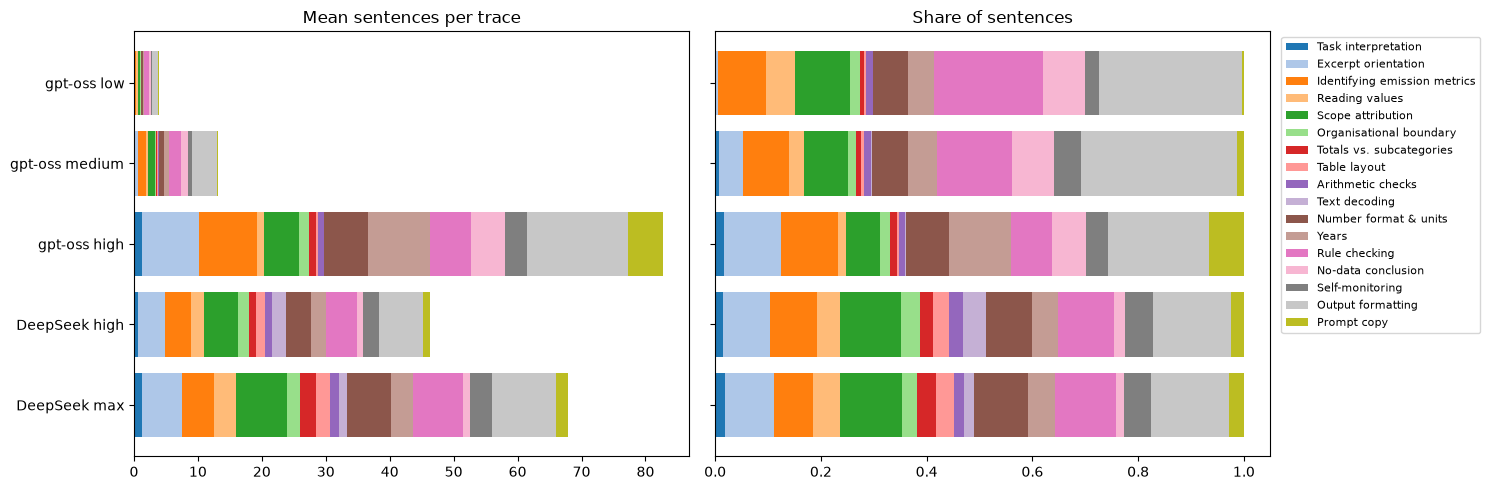

Mean sentences per trace:


,Task interpretation,Excerpt orientation,Identifying emission metrics,Reading values,Scope attribution,Organisational boundary,Totals vs. subcategories,Table layout,Arithmetic checks,Text decoding,Number format & units,Years,Rule checking,No-data conclusion,Self-monitoring,Output formatting,Prompt copy
run,,,,,,,,,,,,,,,,,
gpt-oss low,0.00,0.02,0.35,0.20,0.40,0.07,0.03,0.02,0.05,0.00,0.25,0.19,0.79,0.30,0.10,1.04,0.01
gpt-oss medium,0.08,0.61,1.12,0.37,1.11,0.19,0.13,0.07,0.17,0.02,0.89,0.71,1.86,1.06,0.66,3.86,0.17
gpt-oss high,1.32,8.93,8.94,1.20,5.45,1.55,1.01,0.39,0.86,0.15,6.76,9.78,6.36,5.26,3.45,15.89,5.39
DeepSeek high,0.65,4.18,4.08,2.02,5.30,1.68,1.15,1.43,1.16,2.05,4.02,2.26,4.95,0.93,2.45,6.84,1.13
DeepSeek max,1.23,6.32,5.00,3.47,7.98,1.98,2.41,2.24,1.38,1.27,6.93,3.49,7.79,1.08,3.48,9.95,1.93


Share of traces containing the move at least once:


,Task interpretation,Excerpt orientation,Identifying emission metrics,Reading values,Scope attribution,Organisational boundary,Totals vs. subcategories,Table layout,Arithmetic checks,Text decoding,Number format & units,Years,Rule checking,No-data conclusion,Self-monitoring,Output formatting,Prompt copy
run,,,,,,,,,,,,,,,,,
gpt-oss low,0.00,0.01,0.26,0.07,0.17,0.04,0.02,0.02,0.03,0.00,0.15,0.10,0.68,0.29,0.09,0.95,0.01
gpt-oss medium,0.06,0.45,0.58,0.09,0.30,0.08,0.05,0.05,0.05,0.02,0.31,0.40,0.83,0.62,0.46,1.00,0.13
gpt-oss high,0.73,0.93,0.78,0.15,0.44,0.47,0.25,0.13,0.13,0.06,0.50,0.74,0.92,0.75,0.93,1.00,0.95
DeepSeek high,0.15,0.48,0.77,0.13,0.45,0.18,0.12,0.13,0.08,0.05,0.25,0.28,0.99,0.38,0.72,1.00,0.20
DeepSeek max,0.22,0.60,0.79,0.15,0.47,0.20,0.15,0.15,0.09,0.05,0.29,0.33,1.00,0.42,0.82,1.00,0.24


In [ ]:
counts = (seg.groupby(["trace_id", "move"]).size().unstack(fill_value=0).reindex(columns=MOVES, fill_value=0)
          .reindex(pages.trace_id, fill_value=0))
tm = pages[["trace_id", "run", "report", "page", "category", "n_gold_page", "n_tp_page", "n_fp_page",
            "n_fn_page", "reasoning_words"]].join(counts, on="trace_id")
tm["sentences"] = tm[MOVES].sum(axis=1)

mean_abs = tm.groupby("run", observed=True)[MOVES].mean()
share = mean_abs.div(mean_abs.sum(axis=1), axis=0)
presence = (tm[MOVES] > 0).groupby(tm.run, observed=True).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
cmap = plt.get_cmap("tab20")
for ax, data, title in [(axes[0], mean_abs, "Mean sentences per trace"), (axes[1], share, "Share of sentences")]:
    left = np.zeros(len(data))
    for i, m in enumerate(MOVES):
        ax.barh(data.index, data[m], left=left, color=cmap(i), label=m)
        left += data[m].to_numpy()
    ax.set_title(title)
axes[0].invert_yaxis()
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

print("Mean sentences per trace:")
display(mean_abs.round(2))
print("Share of traces containing the move at least once:")
display(presence.round(2))

## 6. Moves and page outcomes

Pages are grouped as in `run_comparison.ipynb`: *correct, no gold values* (nothing to extract, nothing extracted),
*correct, gold values* (all gold values on the page extracted, no false positive), *error* (at least one false
positive or missed gold value). Longer traces contain more moves of every kind, so the share of sentences is shown
next to the presence rate. Tests are exploratory (no correction for multiple testing).

In [ ]:
CATS = ["correct, no gold values", "correct, gold values", "error"]
pres_cat = (tm[MOVES] > 0).groupby(tm.category).mean().T[CATS]
share_cat = tm[MOVES].div(tm.sentences.clip(lower=1), axis=0).groupby(tm.category).mean().T[CATS]
display(pd.concat({"presence": pres_cat, "share of sentences": share_cat}, axis=1).round(3))

# Gold pages only: correct vs. error, per run. Difference in presence rate (error minus correct).
gold_pages = tm[(tm.n_gold_page > 0)]
rows = []
for run, g in gold_pages.groupby("run", observed=True):
    ok, bad = g[g.category == "correct, gold values"], g[g.category == "error"]
    for m in MOVES:
        a, b = (bad[m] > 0).mean(), (ok[m] > 0).mean()
        rows.append({"run": run, "move": m, "diff": a - b})
diff = pd.DataFrame(rows).pivot(index="move", columns="run", values="diff").reindex(MOVES)[RUN_ORDER]
ns = gold_pages.groupby(["run", "category"], observed=True).size().unstack()
print("Pages with gold values, n per run and outcome:")
display(ns)
print("Presence rate on wrong minus correct gold pages (positive = more frequent in wrong pages):")
display(diff.round(2))

pooled = []
for m in MOVES:
    ok = gold_pages[gold_pages.category == "correct, gold values"][m] > 0
    bad = gold_pages[gold_pages.category == "error"][m] > 0
    table = [[bad.sum(), (~bad).sum()], [ok.sum(), (~ok).sum()]]
    pooled.append({"move": m, "error": bad.mean(), "correct": ok.mean(),
                   "Fisher p (exploratory)": stats.fisher_exact(table)[1]})
print("Pooled over runs:")
display(pd.DataFrame(pooled).set_index("move").round(3))

presence                                  share of sentences                            
category                     correct, no gold values correct, gold values  error correct, no gold values correct, gold values  error
Task interpretation                            0.152                0.305  0.411                   0.007                0.007  0.009
Excerpt orientation                            0.416                0.449  0.536                   0.050                0.020  0.039
Identifying emission metrics                   0.587                0.668  0.679                   0.100                0.056  0.057
Reading values                                 0.047                0.765  0.726                   0.003                0.102  0.079
Scope attribution                              0.282                0.904  0.940                   0.038                0.126  0.166
Organisational boundary                        0.119                0.503  0.548                   0.008                0.026  0.038
Totals vs. subcategories                       0.067                0.310  0.429                   0.003                0.015  0.031
Table layout                                   0.054                0.316  0.399                   0.003                0.012  0.016
Arithmetic checks                              0.033                0.326  0.452                   0.001                0.021  0.027
Text decoding                                  0.022                0.070  0.173                   0.002                0.001  0.002
Number format & units                          0.214                0.957  0.851                   0.021                0.188  0.121
Years                                          0.267                0.936  0.875                   0.023                0.088  0.100
Rule checking                                  0.861                0.882  0.929                   0.190                0.100  0.111
No-data conclusion                             0.485                0.187  0.375                   0.083                0.004  0.010
Self-monitoring                                0.514                0.727  0.708                   0.059                0.041  0.045
Output formatting                              0.996                0.920  0.893                   0.391                0.174  0.123
Prompt copy                                    0.203                0.476  0.518                   0.017                0.019  0.026

Pages with gold values, n per run and outcome:


category,"correct, gold values",error
run,,
gpt-oss low,39,34
gpt-oss medium,45,27
gpt-oss high,22,13
DeepSeek high,53,24
DeepSeek max,28,10


Presence rate on wrong minus correct gold pages (positive = more frequent in wrong pages):


run,gpt-oss low,gpt-oss medium,gpt-oss high,DeepSeek high,DeepSeek max
move,,,,,
Task interpretation,0.00,0.08,0.33,0.27,0.26
Excerpt orientation,-0.02,0.16,0.13,0.29,0.15
Identifying emission metrics,0.11,-0.01,0.06,0.14,0.08
Reading values,0.03,-0.01,0.04,0.09,-0.03
Scope attribution,0.14,-0.01,0.05,0.01,0.04
Organisational boundary,0.03,0.07,0.42,0.08,0.26
Totals vs. subcategories,0.02,0.14,0.17,0.32,0.40
Table layout,0.01,0.19,0.21,0.34,0.16
Arithmetic checks,0.11,0.10,0.27,0.31,0.44


Pooled over runs:


,error,correct,Fisher p (exploratory)
move,,,
Task interpretation,0.389,0.305,0.160
Excerpt orientation,0.509,0.449,0.335
Identifying emission metrics,0.704,0.668,0.604
Reading values,0.759,0.765,1.000
Scope attribution,0.935,0.904,0.394
Organisational boundary,0.565,0.503,0.334
Totals vs. subcategories,0.444,0.310,0.024
Table layout,0.426,0.316,0.060
Arithmetic checks,0.500,0.326,0.004


## 7. Flip analysis: same page, wrong in one run and right in the other

For each comparison (*base* → *comparison*), every page solved by both runs falls into one group:

- **fixed**: error in base, correct in comparison
- **broken**: correct in base, error in comparison
- **both correct (gold)**: both correct on a page with gold values (control group)
- **both error**, **both correct (no gold)**

`gpt-oss low → DeepSeek high` mixes model and reasoning effort; the other comparisons change only the effort.

In [ ]:
COMPARISONS = [("gpt-oss low", "gpt-oss medium"), ("gpt-oss low", "gpt-oss high"),
               ("gpt-oss medium", "gpt-oss high"), ("DeepSeek high", "DeepSeek max"),
               ("gpt-oss low", "DeepSeek high")]
KEY = ["report", "page"]


def pair_frame(base, comp):
    a = tm[tm.run == base].set_index(KEY)
    b = tm[tm.run == comp].set_index(KEY)
    j = a.join(b, how="inner", lsuffix="_base", rsuffix="_comp")
    ok_a, ok_b = j.category_base != "error", j.category_comp != "error"
    gold = j.n_gold_page_base > 0
    j["group"] = np.select([~ok_a & ok_b, ok_a & ~ok_b, ~ok_a & ~ok_b, ok_a & ok_b & gold],
                           ["fixed", "broken", "both error", "both correct (gold)"], "both correct (no gold)")
    j["fixed_fp"] = (j.group == "fixed") & (j.n_fp_page_base > 0)
    j["fixed_fn"] = (j.group == "fixed") & (j.n_fn_page_base > 0)
    j["broken_fp"] = (j.group == "broken") & (j.n_fp_page_comp > 0)
    j["broken_fn"] = (j.group == "broken") & (j.n_fn_page_comp > 0)
    return j.reset_index().assign(base=base, comp=comp)


pairs = {(b, c): pair_frame(b, c) for b, c in COMPARISONS}
GROUPS = ["fixed", "broken", "both error", "both correct (gold)", "both correct (no gold)"]
summary = pd.DataFrame({f"{b} → {c}": p.group.value_counts().reindex(GROUPS, fill_value=0)
                        for (b, c), p in pairs.items()}).T
summary["fixed: had FP"] = [p.fixed_fp.sum() for p in pairs.values()]
summary["fixed: had missed values"] = [p.fixed_fn.sum() for p in pairs.values()]
summary["broken: new FP"] = [p.broken_fp.sum() for p in pairs.values()]
summary["broken: new missed values"] = [p.broken_fn.sum() for p in pairs.values()]
summary

group,fixed,broken,both error,both correct (gold),both correct (no gold),fixed: had FP,fixed: had missed values,broken: new FP,broken: new missed values
gpt-oss low → gpt-oss medium,20,8,34,36,868,12,9,6,2
gpt-oss low → gpt-oss high,12,5,15,17,420,9,3,3,2
gpt-oss medium → gpt-oss high,7,7,13,18,424,6,1,6,2
DeepSeek high → DeepSeek max,4,3,13,26,409,2,2,3,0
gpt-oss low → DeepSeek high,31,14,22,35,857,20,14,11,3


**Which moves appear when a page gets fixed?** For each page pair: presence of a move in the comparison trace
minus presence in the base trace (+1 = only the comparison trace has it, −1 = only the base trace has it), averaged
per group. Because comparison traces are generally longer, the *fixed* column should be read against the
*both correct (gold)* control: moves with a clearly larger value in *fixed* than in the control are the candidates
for what the extra reasoning contributes.

In [ ]:
def move_shift(p):
    d = (p[[f"{m}_comp" for m in MOVES]].to_numpy() > 0).astype(int) - \
        (p[[f"{m}_base" for m in MOVES]].to_numpy() > 0).astype(int)
    d = pd.DataFrame(d, columns=MOVES).assign(group=p.group.values)
    out = d.groupby("group")[MOVES].mean().T.reindex(columns=["fixed", "both correct (gold)", "broken"])
    out["fixed − control"] = out["fixed"] - out["both correct (gold)"]
    out.loc["n pages"] = d.group.value_counts().reindex(out.columns[:3]).tolist() + [np.nan]
    return out


shifts = {f"{b} → {c}": move_shift(p) for (b, c), p in pairs.items()}
for name, s in shifts.items():
    print(f"\n### {name}")
    display(s.round(2))


### gpt-oss low → gpt-oss medium


group,fixed,both correct (gold),broken,fixed − control
Task interpretation,0.15,0.08,0.00,0.07
Excerpt orientation,0.40,0.17,0.25,0.23
Identifying emission metrics,0.35,0.28,0.38,0.07
Reading values,0.05,0.11,0.38,-0.06
Scope attribution,0.20,0.19,0.12,0.01
Organisational boundary,0.30,0.08,0.12,0.22
Totals vs. subcategories,0.10,0.08,0.25,0.02
Table layout,-0.05,0.06,0.38,-0.11
Arithmetic checks,0.15,0.17,0.25,-0.02
Text decoding,0.05,0.06,0.00,-0.01



### gpt-oss low → gpt-oss high


group,fixed,both correct (gold),broken,fixed − control
Task interpretation,0.92,0.59,0.8,0.33
Excerpt orientation,0.50,0.53,0.8,-0.03
Identifying emission metrics,0.75,0.53,0.2,0.22
Reading values,0.17,0.18,0.2,-0.01
Scope attribution,0.25,0.35,0.2,-0.10
Organisational boundary,0.58,0.24,0.8,0.35
Totals vs. subcategories,0.25,0.12,0.8,0.13
Table layout,0.25,0.35,0.6,-0.10
Arithmetic checks,0.33,0.41,0.4,-0.08
Text decoding,0.00,0.06,0.2,-0.06



### gpt-oss medium → gpt-oss high


group,fixed,both correct (gold),broken,fixed − control
Task interpretation,0.57,0.61,0.29,-0.04
Excerpt orientation,0.29,0.44,0.43,-0.16
Identifying emission metrics,0.43,0.33,0.43,0.10
Reading values,0.14,-0.06,0.00,0.20
Scope attribution,0.00,0.06,0.00,-0.06
Organisational boundary,0.14,0.22,0.29,-0.08
Totals vs. subcategories,0.14,0.17,0.14,-0.02
Table layout,0.29,0.33,0.57,-0.05
Arithmetic checks,0.00,0.44,0.00,-0.44
Text decoding,0.29,0.06,0.14,0.23



### DeepSeek high → DeepSeek max


group,fixed,both correct (gold),broken,fixed − control
Task interpretation,0.25,0.31,0.00,-0.06
Excerpt orientation,0.00,0.15,0.00,-0.15
Identifying emission metrics,0.00,0.12,0.00,-0.12
Reading values,0.00,0.08,0.33,-0.08
Scope attribution,0.00,0.08,0.00,-0.08
Organisational boundary,-0.25,-0.08,0.00,-0.17
Totals vs. subcategories,-0.25,0.08,0.00,-0.33
Table layout,0.00,0.19,0.00,-0.19
Arithmetic checks,0.00,-0.08,0.33,0.08
Text decoding,-0.50,0.00,0.00,-0.50



### gpt-oss low → DeepSeek high


group,fixed,both correct (gold),broken,fixed − control
Task interpretation,0.68,0.40,0.86,0.28
Excerpt orientation,0.74,0.43,0.71,0.31
Identifying emission metrics,0.42,0.29,0.43,0.13
Reading values,0.35,0.20,0.29,0.15
Scope attribution,0.16,0.17,0.21,-0.01
Organisational boundary,0.68,0.66,0.64,0.02
Totals vs. subcategories,0.48,0.26,0.79,0.23
Table layout,0.55,0.31,0.57,0.23
Arithmetic checks,0.35,0.17,0.21,0.18
Text decoding,0.26,0.06,0.50,0.20


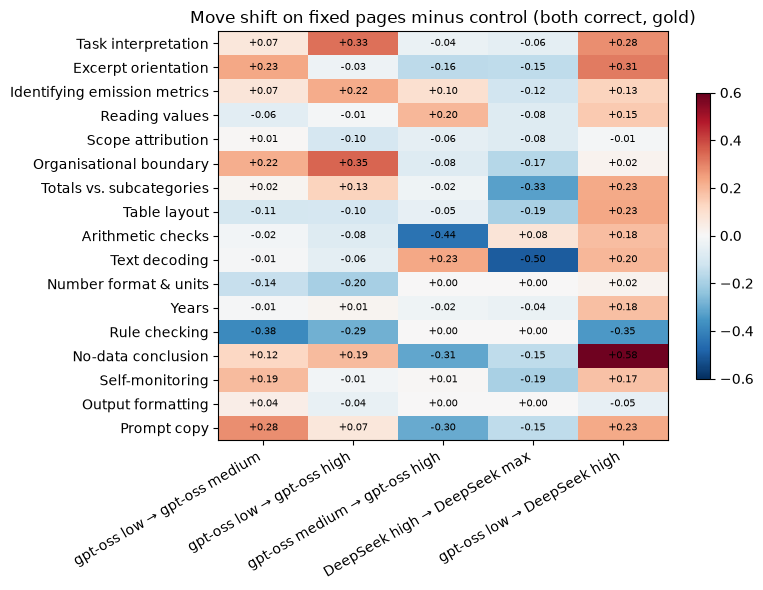

In [ ]:
fc = pd.DataFrame({k: shifts[k]["fixed − control"].drop("n pages") for k in shifts})
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(fc.to_numpy(dtype=float), cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(fc.shape[1]), fc.columns, rotation=30, ha="right")
ax.set_yticks(range(fc.shape[0]), fc.index)
for i in range(fc.shape[0]):
    for j in range(fc.shape[1]):
        ax.text(j, i, f"{fc.iat[i, j]:+.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Move shift on fixed pages minus control (both correct, gold)")
fig.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.show()

## 8. Case browser

`flip_table(base, comp, group)` lists the pages of a group with what each run extracted against the gold
standard. `show_flip(base, comp, report, page)` prints both traces sentence by sentence with the move label of
each sentence (consecutive prompt copies are collapsed).

In [ ]:
EVAL_COLS = ["ReportName", "scope_man", "year_man", "page_man", "page_number_used_by_llm", "value_man",
             "extracted_value_from_llm", "extracted_unit_from_llm", "error_value"]


def norm_page(value):
    text = str(value).strip()
    if text in ("", "nan", "None"):
        return None
    return text[:-2] if re.fullmatch(r"\d+\.0", text) else text


ev = pd.concat([pd.read_csv(d / "eval_results_vs_benchmark.csv", usecols=EVAL_COLS, dtype=str).assign(run=r)
                for r, d in EVAL_DIRS.items()], ignore_index=True)
ev["err"] = ev.error_value.str.replace("_value", "").map(
    {"true_positive": "TP", "false_positive": "FP", "false_negative": "FN", "true_negative": "TN"})
ev["page_used"] = ev.page_number_used_by_llm.map(norm_page)
ev["page_gold"] = ev.page_man.map(norm_page)


def page_cells(run, report, page):
    e = ev[(ev.run == run) & (ev.ReportName == report) & (ev.err != "TN")]
    e = e[(e.page_used == str(page)) | ((e.page_gold == str(page)) & (e.err == "FN"))]
    return e.set_index(["scope_man", "year_man"])[["value_man", "extracted_value_from_llm", "err"]]


def flip_table(base, comp, group="fixed"):
    p = pairs[(base, comp)]
    p = p[p.group == group].sort_values("sentences_comp")
    rows = []
    for r in p.itertuples():
        a, b = page_cells(base, r.report, r.page), page_cells(comp, r.report, r.page)
        rows.append({"report": r.report, "page": r.page, "gold values": r.n_gold_page_base,
                     f"{base}": ", ".join(f"{s}/{y}:{e}" for (s, y), e in a.err.items()) or "-",
                     f"{comp}": ", ".join(f"{s}/{y}:{e}" for (s, y), e in b.err.items()) or "-",
                     "sentences base": r.sentences_base, "sentences comp": r.sentences_comp})
    return pd.DataFrame(rows)


def annotated(run, report, page, max_sentences=60):
    tid = tm[(tm.run == run) & (tm.report == report) & (tm.page == str(page))].trace_id
    s = seg[seg.trace_id == tid.iloc[0]].sort_values("pos")
    lines, copies = [], 0
    for r in s.itertuples():
        if r.move == "Prompt copy":
            copies += 1
            continue
        if copies:
            lines.append(f"    [prompt copy ×{copies}]")
            copies = 0
        lines.append(f"    [{r.move}] {r.text}")
    if copies:
        lines.append(f"    [prompt copy ×{copies}]")
    more = len(lines) - max_sentences
    return "\n".join(lines[:max_sentences]) + (f"\n    ... {more} more sentences" if more > 0 else "")


def show_flip(base, comp, report, page, max_sentences=60):
    for run in (base, comp):
        r = tm[(tm.run == run) & (tm.report == report) & (tm.page == str(page))].iloc[0]
        print("=" * 110)
        print(f"{run} | {report} | page {page} | {r.category} | sentences: {r.sentences}")
        cells = page_cells(run, report, page)
        if len(cells):
            print(cells.to_string())
        print(annotated(run, report, page, max_sentences))
        ans = pages[(pages.run == run) & (pages.report == report) & (pages.page == str(page))].answer.iloc[0]
        print("  answer:", str(ans)[:600])


fixed_med = flip_table("gpt-oss low", "gpt-oss medium", "fixed")
display(fixed_med)

,report,page,gold values,gpt-oss low,gpt-oss medium,sentences base,sentences comp
0,ichor holdings_2021_report.pdf,17,0,"1/2021:FP, 2lb/2021:FP",-,8,11
1,allfunds group_2021_report.pdf,126,0,"1/2020:TP, 2lb/2020:FP, 3/2020:FP",-,12,14
2,toshiba tec corp_2022_report.pdf,34,0,"1/2017:FP, 1/2018:FP, 1/2019:FP, 1/2020:FP, 1/2021:FP",-,14,18
3,cubesmart reit_2021_report.pdf,20,0,"1/2020:FP, 1/2021:FP, 2lb/2020:FP, 2lb/2021:FP",-,10,19
4,smith (ds) plc_2021_report.pdf,63,0,1/2021:FP,-,9,21
5,smith (ds) plc_2021_report.pdf,53,0,"1/2015:FP, 2mb/2015:FP",-,10,24
6,varta ag_2021_report.pdf,27,0,2lb/2021:FP,-,7,25
7,apollo commercial real estate fina_2019_report.pdf,33,0,"1/2019:FP, 2lb/2019:FP",-,5,25
8,aixtron_2020_report.pdf,50,4,"1/2020:TP, 2lb/2020:TP, 3/2019:FN, 3/2020:TP","1/2019:TP, 1/2020:TP, 2lb/2019:TP, 2lb/2020:TP, 3/2019:TP, 3/2020:TP",3,26
9,addtech_2022_report.pdf,73,4,"1/2019:FN, 1/2020:FP, 1/2021:FP, 1/2022:FP, 2lb/2019:FN, 2lb/2020:FP, 2lb/2021:FP, 2lb/2022:FP, 2mb/2020:FN, 2mb/2021:FP, 2mb/2022:FP, 3/2019:FN, 3/2020:FP,...","1/2019:TP, 1/2020:TP, 1/2021:TP, 2lb/2019:TP, 2lb/2020:TP, 2lb/2021:TP, 2mb/2020:TP, 2mb/2021:TP, 3/2019:TP, 3/2020:TP, 3/2021:TP",11,31


In [ ]:
ex = fixed_med.iloc[0]
show_flip("gpt-oss low", "gpt-oss medium", ex.report, ex.page)

gpt-oss low | ichor holdings_2021_report.pdf | page 17 | error | sentences: 8
                   value_man extracted_value_from_llm err
scope_man year_man                                       
1         2021           NaN                    296.0  FP
2lb       2021           NaN                   5874.0  FP
    [Rule checking] We need extract Scope1 296, Scope2 5,874, total 6,170 but total is sum of scopes not needed.
    [Organisational boundary] Only whole company?
    [Organisational boundary] This is US sites only, not whole company, but likely still whole?
    [Organisational boundary] Probably not whole company, but it's the only data.
    [Rule checking] We'll extract anyway.
    [Number format & units] Units metric tonnes CO2e.
    [Rule checking] Scope2 unspecified -> location-based.
    [Scope attribution] No Scope3 total.
  answer: {
  "KPI_Entries": [
    {
      "year": 2021,
      "kpi_name": "1",
      "value": 296,
      "unit": "tCO2e"
    },
    {
      "year": 2021,

In [ ]:
display(flip_table("DeepSeek high", "DeepSeek max", "fixed"))
display(flip_table("gpt-oss low", "gpt-oss high", "broken"))

,report,page,gold values,DeepSeek high,DeepSeek max,sentences base,sentences comp
0,ctbc holding_2020_report.pdf,61,15,"1/2016:TP, 1/2017:TP, 1/2018:TP, 1/2019:TP, 1/2020:TP, 2lb/2016:TP, 2lb/2017:TP, 2lb/2018:TP, 2lb/2019:TP, 2lb/2020:TP, 3/2016:FN, 3/2017:FN, 3/2018:FN, 3/2...","1/2016:TP, 1/2017:TP, 1/2018:TP, 1/2019:TP, 1/2020:TP, 2lb/2016:TP, 2lb/2017:TP, 2lb/2018:TP, 2lb/2019:TP, 2lb/2020:TP, 3/2016:TP, 3/2017:TP, 3/2018:TP, 3/2...",193,512
1,sumitomo corporation_2021_report.pdf,121,8,"2lb/2017:TP, 2lb/2018:TP, 2lb/2019:TP, 2lb/2020:TP, 3/2017:FN, 3/2018:FN, 3/2019:FN, 3/2020:FN","2lb/2017:TP, 2lb/2018:TP, 2lb/2019:TP, 2lb/2020:TP, 3/2017:TP, 3/2018:TP, 3/2019:TP, 3/2020:TP",679,612
2,tokyu construction_2018_report.pdf,6,0,"1/2014:FP, 1/2015:FP, 1/2016:FP, 1/2017:FP, 1/2018:FP, 2lb/2014:FP, 2lb/2015:FP, 2lb/2016:FP, 2lb/2017:FP, 2lb/2018:FP",-,1376,946
3,dksh holding_2021_report.pdf,17,0,"1/2019:FP, 1/2020:FP, 1/2021:FP, 2mb/2019:FP, 2mb/2020:FP, 2mb/2021:FP","1/2019:TP, 1/2020:TP, 1/2021:TP, 2mb/2019:TP, 2mb/2020:TP, 2mb/2021:TP",888,1057


,report,page,gold values,gpt-oss low,gpt-oss high,sentences base,sentences comp
0,healius ltd_2022_report.pdf,50,4,"1/2021:TP, 1/2022:TP, 2lb/2021:TP, 2lb/2022:TP","1/2021:TP, 1/2022:TP, 2lb/2021:FN, 2lb/2022:FN",10,86
1,ctbc holding_2020_report.pdf,57,0,-,3/2020:FP,8,118
2,apollo commercial real estate fina_2019_report.pdf,40,0,-,"1/2019:FP, 2lb/2019:FP",4,279
3,tkh group_2018_report.pdf,31,0,-,2lb/2018:FP,16,299
4,kureha corp_2020_report.pdf,8,9,"1/2017:TP, 1/2018:TP, 1/2019:TP, 2lb/2017:TP, 2lb/2018:TP, 2lb/2019:TP, 3/2017:TP, 3/2018:TP, 3/2019:TP","1/2017:FN, 1/2018:TP, 1/2019:TP, 2lb/2017:FN, 2lb/2018:TP, 2lb/2019:TP, 3/2017:FN, 3/2018:TP, 3/2019:TP",19,467


## 9. Export

In [ ]:
seg.drop(columns=["rel_pos"]).to_parquet(TOPIC_DIR / "sentence_moves.parquet", index=False)
tm.assign(run=tm.run.astype(str)).to_parquet(TOPIC_DIR / "trace_moves.parquet", index=False)
pd.concat(pairs.values(), ignore_index=True)[
    ["base", "comp", "report", "page", "group", "n_gold_page_base", "n_fp_page_base", "n_fn_page_base",
     "n_fp_page_comp", "n_fn_page_comp", "sentences_base", "sentences_comp"]
].to_csv(TOPIC_DIR / "page_flips.csv", index=False)
topic_info.to_csv(TOPIC_DIR / "topic_info.csv", index=False)
print("Written to", TOPIC_DIR.relative_to(ROOT))

Written to analysis/derived/topics


## 10. UMAP of topic groups (reasoning moves)

2D UMAP on the same MiniLM embeddings as the topic model, coloured by the codebook
**move** (section 4). Prompt-copy sentences are included as their own colour.

Edit `MOVE_TOPICS` above to change the grouping — then re-run that cell and this plot.

In [ ]:
from umap import UMAP

# Reuse the fitted unique-sentence embeddings (section 2).
plot = sent[["text", "move", "prompt_copy"]].copy()
assert len(plot) == len(E)

umap_path = TOPIC_DIR / f"umap2d_{key}.npy"
if umap_path.exists():
    xy = np.load(umap_path)
else:
    xy = UMAP(
        n_neighbors=15, n_components=2, min_dist=0.1,
        metric="cosine", random_state=SEED,
    ).fit_transform(E)
    np.save(umap_path, xy)

plot["x"], plot["y"] = xy[:, 0], xy[:, 1]

# Subsample for readability
rng = np.random.default_rng(SEED)
idx = rng.choice(len(plot), size=min(40_000, len(plot)), replace=False)
sub = plot.iloc[idx].copy()
moves = [m for m in MOVES if m in set(sub["move"])]
colors = plt.cm.tab20(np.linspace(0, 1, len(moves)))
move_to_color = dict(zip(moves, colors))

fig, ax = plt.subplots(figsize=(11, 8))
for m in moves:
    pts = sub[sub.move == m]
    ax.scatter(pts.x, pts.y, s=4, alpha=0.35, linewidths=0,
               color=move_to_color[m], label=m)
ax.set_title("UMAP — coloured by reasoning move (codebook)")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(markerscale=3, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

# Compact view: only a few example moves highlighted
highlight = [
    "Scope attribution", "Rule checking", "Reading values",
    "Output formatting", "Prompt copy",
]
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(sub.x, sub.y, s=2, alpha=0.08, c="lightgray", linewidths=0)
for m in highlight:
    if m not in move_to_color:
        continue
    pts = sub[sub.move == m]
    ax.scatter(pts.x, pts.y, s=6, alpha=0.45, linewidths=0,
               color=move_to_color[m], label=m)
ax.set_title("UMAP — selected moves highlighted")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(markerscale=2.5, fontsize=9, loc="best")
plt.tight_layout()
plt.show()

## Limitations

- The topic → move grouping is a manual interpretation of 40 clusters; some clusters mix moves. It is a starting
  point for a codebook, not a validated annotation. A sample of sentences should be labelled by hand (or by an
  LLM judge with this codebook) to measure agreement.
- Sentence embeddings partly cluster by vocabulary (e.g. "Scope 2", "fiscal year"), so a move is detected when it
  is *verbalised*, not when it is performed silently.
- Flip groups contain few pages; differences are descriptive.
- No reasoning-off run yet; all comparisons are between reasoning budgets (and one between models).